# Diagrams: speciation, Pourbaix, phase transitions, Ellingham

`discopt.speciation.plot` builds diagrams from complete equilibrium calculations. Every point on every diagram is a full solve, so aqueous complexes, activity corrections and solid phases all come from one consistent model.

**You will learn to**
- sweep one variable (pH, temperature, CO₂ pressure) and plot speciation, saturation index and solubility along it;
- compute a Pourbaix (Eh–pH) diagram and read its fields and water stability lines;
- draw an Ellingham diagram from $\log K(T)$ functions.

**Prerequisites.** [`01-getting-started.ipynb`](https://github.com/jkitchin/discopt-speciation/blob/main/examples/01-getting-started.ipynb), which covers systems, `equilibrate`, saturation index (SI) and complementarity. [`03-databases-and-your-own-data.ipynb`](https://github.com/jkitchin/discopt-speciation/blob/main/examples/03-databases-and-your-own-data.ipynb) shows how `db.system` selects species from a database.

**Data.** All aqueous calculations use [`phreeqc.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/phreeqc.dat) (Parkhurst and Appelo 2013, [doi:10.3133/tm6A43](https://doi.org/10.3133/tm6A43)). Amounts are in mol per kg of water (mol/kgw).

**Runtime.** The Pourbaix cell does about 1,400 equilibrium solves and takes 2–3 minutes. The other cells take seconds.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from discopt.speciation import PhreeqcDatabase, plot, fit

db = PhreeqcDatabase.load("phreeqc.dat")

## Iron speciation and ferrihydrite precipitation vs pH

**Goal.** Follow 1 mmol/kgw of iron (added with 3 mmol/kgw chloride) from pH 2 to 12. `Fe(OH)3(a)` is amorphous ferric hydroxide (ferrihydrite) and is allowed to precipitate.

**Terms.**
- **pe** $= -\log_{10} a_{e^-}$ sets how oxidizing the solution is. Higher pe favours Fe(III), lower pe favours Fe(II). Holding pe = 4 fixes the redox level, so the Fe(II)/Fe(III) split is computed, not assumed from the salt added.
- **SI** (saturation index) $= \log_{10}(\mathrm{IAP}/K_{sp})$. A solid is present only when SI = 0 and absent when SI < 0 (complementarity).

**Code.** `plot.sweep(system, "pH", values, ...)` runs one `equilibrate` per value. `Sweep.get(quantity)` returns an array along the sweep, for example `"SI:Fe(OH)3(a)"` or `"solids:Fe(OH)3(a)"`. `plot.plot_sweep` plots molalities on a log axis, with solids dashed.

all converged: True


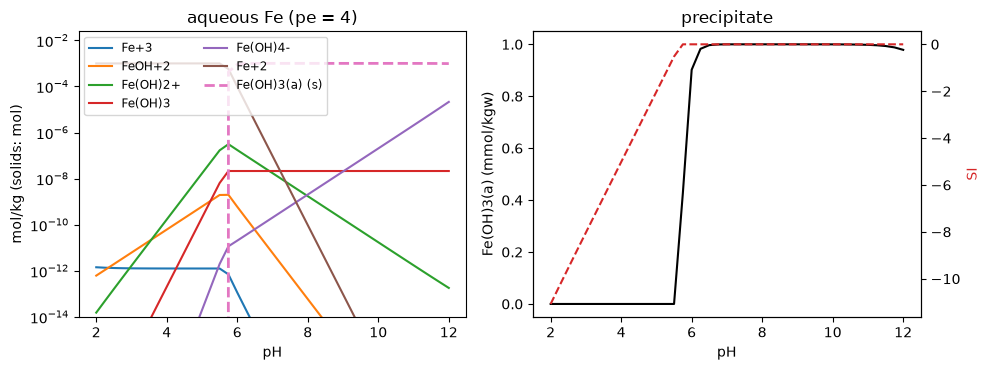

In [2]:
fe = db.system(["Fe", "Cl"], phases=["Fe(OH)3(a)"])
pHs = np.linspace(2, 12, 41)
sw = plot.sweep(fe, "pH", pHs, amounts={"Fe": 1e-3, "Cl": 3e-3}, pe=4)
print("all converged:", sw.converged.all())
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8))
plot.plot_sweep(sw, ["Fe+3", "FeOH+2", "Fe(OH)2+", "Fe(OH)3", "Fe(OH)4-", "Fe+2"], ax=axs[0], floor=1e-14)
axs[0].set_title("aqueous Fe (pe = 4)")
# right panel: amount of precipitate (black, left axis) and its saturation index (red, right axis)
axs[1].plot(pHs, sw.get("solids:Fe(OH)3(a)") * 1e3, "k")
axs[1].set(xlabel="pH", ylabel="Fe(OH)3(a) (mmol/kgw)", title="precipitate")
ax2 = axs[1].twinx()
ax2.plot(pHs, sw.get("SI:Fe(OH)3(a)"), "C3--")
ax2.set_ylabel("SI", color="C3")
plt.tight_layout()

**Result.**
- **Low pH.** Below pH ≈ 5.5 all the iron is dissolved, and at pe = 4 almost all of it is Fe²⁺ (1.0 × 10⁻³ mol/kgw). Fe³⁺ is only about 10⁻¹² mol/kgw. SI of Fe(OH)₃(a) rises from −11 at pH 2 to −0.5 at pH 5.5.
- **Onset of precipitation.** SI reaches 0 between pH 5.5 and 5.75, and ferrihydrite appears at the same point. By pH 6.25 about 98 % of the iron is solid. The solid amount is zero wherever SI < 0, which is complementarity at work.
- **Above the onset.** Dissolved Fe(OH)₃ is fixed by the solid at about 2 × 10⁻⁸ mol/kgw. Fe²⁺ falls steeply because ferrihydrite now limits Fe(III) and pe ties Fe(II) to it.
- **High pH.** Fe(OH)₄⁻ grows about tenfold per pH unit (2 × 10⁻⁵ mol/kgw at pH 12), so a little solid redissolves (0.98 mmol/kgw at pH 12).

## Pourbaix (Eh–pH) diagram for iron

**What it shows.** A Pourbaix diagram (Pourbaix 1966) maps which species or solid dominates as a function of acidity (pH, x-axis) and oxidizing power (y-axis). The y-axis is the redox potential Eh in volts, related to pe by $E_h = (RT\ln 10/F)\,\mathrm{pe} \approx 0.0592\,\mathrm{pe}$ V at 25 °C. Oxidized species (Fe³⁺, ferrihydrite) sit at the top and reduced species (Fe²⁺) at the bottom.

**Water stability lines (dashed).** Water is stable only between two lines:
- Above $E_h = 1.23 - 0.0592\,\mathrm{pH}$ it is oxidized to O₂ (1 atm).
- Below $E_h = -0.0592\,\mathrm{pH}$ it is reduced to H₂ (1 atm).

Fields outside these lines cannot persist in open contact with water.

**Method.** `plot.pourbaix` solves the system at every (pH, pe) grid point. It labels each point with the candidate that has the largest amount: molality for aqueous species, mol/kgw for solids. Here there are 31 × 31 points at 10⁻³ mol/kgw Fe and a coarser 21 × 21 grid at 10⁻⁶ mol/kgw to save time.

**Dependence on total concentration.** Textbook diagrams are drawn at one assumed activity. These boundaries move with the total iron, which the second panel shows.

0.001: 961 points in 82 s, fields: ['Fe(OH)3(a)', 'Fe(OH)4-', 'Fe+2', 'Fe+3', 'FeOH+', 'FeOH+2']


1e-06: 441 points in 47 s, fields: ['Fe(OH)2+', 'Fe(OH)3(a)', 'Fe(OH)4-', 'Fe+2', 'Fe+3', 'FeOH+', 'FeOH+2']


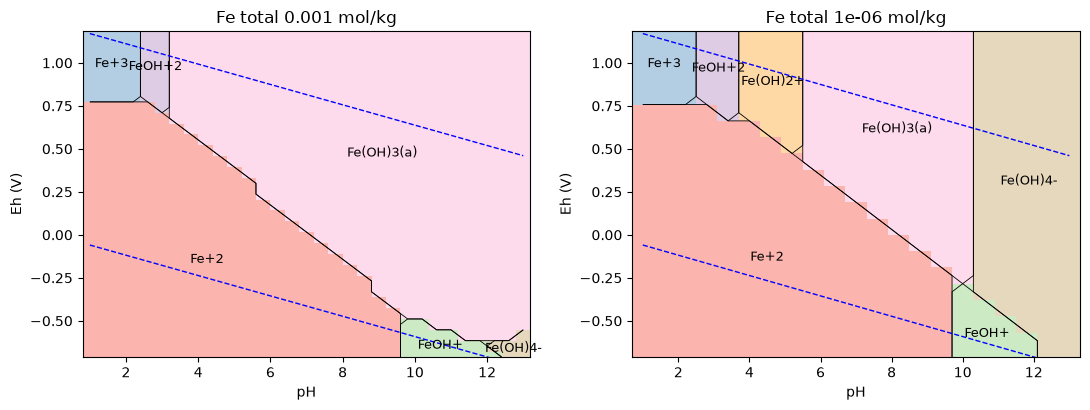

In [3]:
# candidate species/solids to compare; keep only names that exist in this system
cands = [n for n in ["Fe+2", "Fe+3", "FeOH+", "FeOH+2", "Fe(OH)2+", "Fe(OH)3", "Fe(OH)4-", "Fe(OH)3(a)"] if n in fe]
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, total, n in [(axs[0], 1e-3, 31), (axs[1], 1e-6, 21)]:   # (axis, total Fe in mol/kgw, grid points per axis)
    t = time.time()
    pH_grid = np.linspace(1, 13, n)
    pe_grid = np.linspace(-12, 20, n)   # Eh from about -0.71 to +1.18 V
    pr, _ = plot.pourbaix(fe, cands, pH_grid, pe_grid, amounts={"Fe": total, "Cl": 3 * total}, ax=ax)
    ax.set_title(f"Fe total {total:g} mol/kg")
    # pr.grid holds an index into pr.labels for each point (-1 = not converged)
    fields = sorted({pr.labels[i] for i in np.unique(pr.grid) if i >= 0})
    print(f"{total:g}: {pr.grid.size} points in {time.time() - t:.0f} s, fields: {fields}")
plt.tight_layout()

**Result.**
- **Reading the diagram.** Between the water lines, Fe²⁺ fills the low-pH, low-Eh region and ferrihydrite, Fe(OH)₃(a), the oxidized neutral-to-basic region. Fe³⁺ and FeOH²⁺ only appear at pH below about 3 and Eh above about 0.75 V. The sloped Fe²⁺/Fe(OH)₃(a) boundary is the reaction Fe(OH)₃ + 3H⁺ + e⁻ = Fe²⁺ + 3H₂O, which involves both electrons and protons.
- **At 10⁻³ mol/kgw** there are six fields. Ferrihydrite spans pH ≈ 3 to 13 at the top of the diagram, and Fe(OH)₄⁻ is confined to a corner at pH 13, low Eh.
- **At 10⁻⁶ mol/kgw** the ferrihydrite field shrinks to pH ≈ 5.5–10. Fe(OH)₂⁺ gets its own field (pH ≈ 3.7–5.5, high Eh), and Fe(OH)₄⁻ takes over above pH ≈ 10. With less iron, the solid is stable over a narrower range.
- **Caveats.**
  - The step-like boundaries come from the coarse grid. Use more points for smooth lines, at a cost of one solve per point.
  - The FeOH⁺ field sits at very low Eh, around the H₂ line, at the edge of water stability.
  - Metallic iron is not a candidate here, so no Fe(s) field appears.

## Gypsum–anhydrite transition with temperature

The previous sections varied pH and pe. A sweep can also run over temperature, and then the stable solid itself can change.

**Setup.** Gypsum (CaSO₄·2H₂O) and anhydrite (CaSO₄) are both candidate solids. We add 0.5 mol of gypsum per kg of water, far more than dissolves, so one solid is always present. Temperature is swept from 0 to 100 °C in 4 °C steps. Each phase's $\log K(T)$ comes from [`phreeqc.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/phreeqc.dat). Nothing tells the solver where the transition is.

anhydrite first stable at about 56 °C in this grid (phreeqc.dat data)


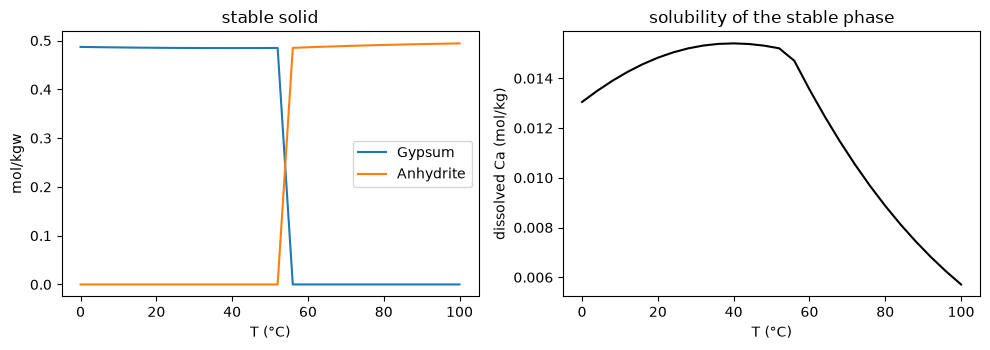

In [4]:
cs = db.system(["Ca", "S(6)"], phases=["Gypsum", "Anhydrite"])
Ts = np.linspace(0, 100, 26) + 273.15
swT = plot.sweep(cs, "T", Ts, amounts={"Gypsum": 0.5})
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
tC = Ts - 273.15
axs[0].plot(tC, swT.get("solids:Gypsum"), label="Gypsum")
axs[0].plot(tC, swT.get("solids:Anhydrite"), label="Anhydrite")
axs[0].set(xlabel="T (°C)", ylabel="mol/kgw", title="stable solid")
axs[0].legend()
# dissolved Ca = sum of the molalities of the main Ca-bearing aqueous species
ca_dissolved = fit.total("Ca+2", "CaSO4", "CaHSO4+")
axs[1].plot(tC, swT.get(ca_dissolved), "k")
axs[1].set(xlabel="T (°C)", ylabel="dissolved Ca (mol/kg)", title="solubility of the stable phase")
plt.tight_layout()
switch = tC[np.argmax(swT.get("solids:Anhydrite") > 0)]
print(f"anhydrite first stable at about {switch:.0f} °C in this grid (phreeqc.dat data)")

**Result.**
- **Stable solid.** Gypsum is the only solid up to 52 °C and anhydrite from 56 °C, so the transition lies between these grid points with [`phreeqc.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/phreeqc.dat) data. Below the transition anhydrite is undersaturated (SI = −0.30 at 25 °C), and above it gypsum is.
- **Solubility.** The right panel follows whichever solid is stable. Dissolved Ca rises to about 0.0154 mol/kgw near 40 °C (gypsum), then falls to about 0.006 mol/kgw at 100 °C (anhydrite, whose solubility decreases with temperature). The kink near 55 °C marks the phase change.

## Open-system calcite: pH and solubility vs CO₂ partial pressure

**Goal.** Find the pH and dissolved calcium of water in equilibrium with calcite (CaCO₃) and a CO₂ gas phase whose pressure is held fixed ("open system"). This is the textbook picture of water in contact with limestone.

**Code.** The sweep variable `"fixed:CO2(g)"` holds $\log_{10} p_{\mathrm{CO_2}}$ (atm) at each value, here from −5 to 0 (atmospheric air is about −3.4). One mole of calcite per kg of water is an excess, so calcite stays present.

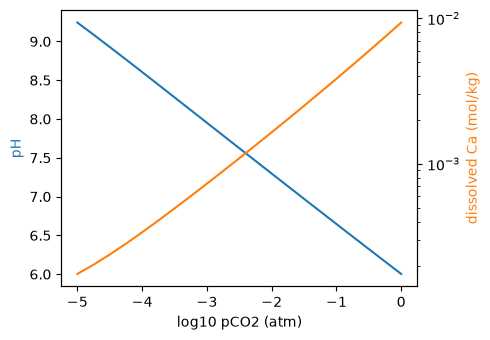

In [5]:
cal = db.system(["Ca", "C(4)"], phases=["Calcite", "CO2(g)"])
lps = np.linspace(-5, 0, 21)
swc = plot.sweep(cal, "fixed:CO2(g)", lps, amounts={"Calcite": 1.0})
ca_dissolved = fit.total("Ca+2", "CaHCO3+", "CaCO3", "CaOH+")
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(lps, swc.get("pH"), "C0")
ax.set_xlabel("log10 pCO2 (atm)")
ax.set_ylabel("pH", color="C0")
ax2 = ax.twinx()   # second y-axis on the right
ax2.semilogy(lps, swc.get(ca_dissolved), "C1")
ax2.set_ylabel("dissolved Ca (mol/kg)", color="C1")
plt.tight_layout()

**Result.** More CO₂ makes the water more acidic and dissolves more calcite (CaCO₃ + CO₂ + H₂O = Ca²⁺ + 2HCO₃⁻).

| log pCO₂ (atm) | pH | dissolved Ca (mol/kgw) |
|---|---|---|
| −5 | 9.24 | 1.8 × 10⁻⁴ |
| −3.5 (about air) | 8.28 | 4.9 × 10⁻⁴ |
| −2 (soil gas) | 7.30 | 1.6 × 10⁻³ |
| 0 | 6.00 | 9.3 × 10⁻³ |

pH falls almost linearly with log pCO₂, and solubility rises about 50-fold over the range.

## Ellingham diagram

The last diagram leaves aqueous chemistry. It uses the same $\log K(T)$ machinery for high-temperature oxidation reactions.

**What is plotted.** An Ellingham diagram (Ellingham 1944) plots the standard Gibbs energy of oxide formation, $\Delta G^\circ(T) = -RT\ln 10\,\log K(T)$, against temperature. Every reaction is written per mole of O₂ so the lines can be compared. `plot.ellingham` accepts `Reaction` objects with temperature data, or any function `T -> log10 K`.

**Reading the diagram.**
- **Height.** Lower lines mean more stable oxides. A metal (or C, or H₂) can reduce the oxide of any element whose line lies *above* its own at that temperature. Where two lines cross, the direction of reduction reverses.
- **Slope.** With $\Delta G^\circ \approx \Delta H^\circ - T\Delta S^\circ$, the slope is $-\Delta S^\circ$. Metal oxidation consumes O₂ gas, so $\Delta S^\circ < 0$ and those lines rise. C + O₂ = CO₂ keeps the moles of gas constant, so its line is flat. 2C + O₂ = 2CO doubles the moles of gas, so its line falls.

**Data used here.** The curves are rounded linear fits $\Delta G^\circ \approx A + BT$ (A in kJ/mol O₂, B in kJ/(mol O₂·K)) of standard tabulated data. They are for illustration only, not for design calculations, and ignore melting.

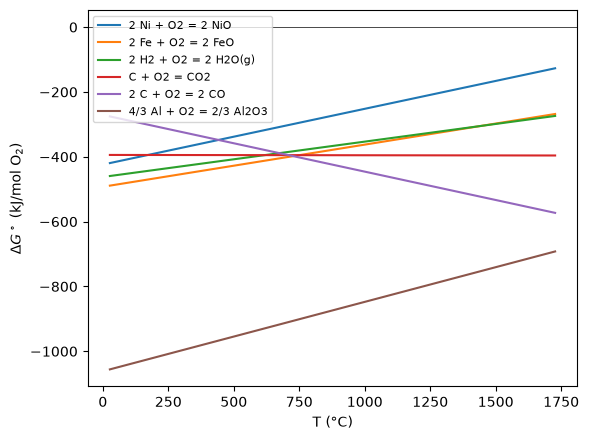

In [6]:
R = 8.314462618e-3   # gas constant, kJ/(mol K)

# turn a fit dG = A + B*T (kJ/mol O2) into a function T -> log10 K
def from_linear(A, B):
    return lambda T: -(A + B * T) / (R * T * np.log(10))

oxides = {
    "2 Ni + O2 = 2 NiO": from_linear(-471.0, 0.172),
    "2 Fe + O2 = 2 FeO": from_linear(-528.0, 0.130),
    "2 H2 + O2 = 2 H2O(g)": from_linear(-492.0, 0.109),
    "C + O2 = CO2": from_linear(-394.0, -0.001),
    "2 C + O2 = 2 CO": from_linear(-223.0, -0.175),
    "4/3 Al + O2 = 2/3 Al2O3": from_linear(-1120.0, 0.214),
}
fig, ax = plt.subplots(figsize=(6, 4.5))
# every reaction is already written per 1 mol O2; passing `per` labels the axis in kJ/mol O2
T, dG = plot.ellingham(oxides, np.linspace(300, 2000, 60), per={name: 1 for name in oxides}, ax=ax)
ax.legend(fontsize=8)
plt.tight_layout()

**Result.** The axis runs from 27 to 1727 °C.
- **Aluminium.** Al₂O₃ lies far below every other line, so aluminium reduces all the other oxides shown at every temperature.
- **Carbon and iron.** The falling 2C + O₂ = 2CO line crosses FeO near 730 °C. Above that temperature carbon can reduce FeO to iron, which is the basis of the blast furnace. It crosses NiO already near 440 °C.
- **Hydrogen and iron.** The H₂/H₂O line lies above FeO until about 1440 °C, where the two lines cross. With these fits and all gases at 1 atm, H₂ does not reduce FeO at lower temperatures.

## Summary

| diagram | call | what it shows |
|---|---|---|
| sweep | `sw = plot.sweep(system, variable, values, **conditions)`, then `plot.plot_sweep(sw, species)` or `sw.get(quantity)` | any result along pH, pe, T, P, an amount or `"fixed:<gas>"` |
| predominance / Pourbaix | `pr, ax = plot.pourbaix(system, candidates, pH, pe, amounts=...)` | dominant species or solid at each (pH, Eh), with water lines; `plot.predominance` for any other pair of axes |
| Ellingham | `T, dG = plot.ellingham(reactions, T, per=...)` | $\Delta G^\circ(T)$ per mol O₂; lower line = more stable oxide |

**Things to remember.**
- Every point is a full equilibrium solve, so boundaries depend on total concentrations and activity corrections.
- Grid size sets both cost and boundary smoothness.

**Next steps.**
- [`06-rare-earths-and-thorium.ipynb`](https://github.com/jkitchin/discopt-speciation/blob/main/examples/06-rare-earths-and-thorium.ipynb) applies sweeps to Th and rare-earth solubility with [`llnl.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/llnl.dat) and [`sit.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/sit.dat).
- [`docs/diagrams.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/diagrams.md) gives the full API, including other sweep variables and per-atom weighting of candidates.
- [`docs/databases.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/databases.md) covers choosing a database.

## References

- Parkhurst, D.L., and Appelo, C.A.J. (2013). *Description of input and examples for PHREEQC version 3.* USGS Techniques and Methods 6-A43. [doi:10.3133/tm6A43](https://doi.org/10.3133/tm6A43). Source of [`phreeqc.dat`](https://github.com/jkitchin/discopt-speciation/blob/main/src/discopt/speciation/data/phreeqc.dat) and its conventions.
- Pourbaix, M. (1966). *Atlas of Electrochemical Equilibria in Aqueous Solutions.* Pergamon Press, Oxford.
- Ellingham, H.J.T. (1944). Reducibility of oxides and sulphides in metallurgical processes. *Journal of the Society of Chemical Industry* 63(5), 125–133.

The full bibliography, with the sources for each database and activity model, is in [`docs/references.md`](https://github.com/jkitchin/discopt-speciation/blob/main/docs/references.md).